In [1]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('seaborn-v0_8-whitegrid')
plt.rc('figure', autolayout=True)
plt.rc('axes', labelweight='bold', labelsize='large',
       titleweight='bold', titlesize=18, titlepad=10)

In [2]:
import pandas as pd

concrete = pd.read_csv('../datasets/dl-course-data/concrete.csv')
concrete.head()

,Cement,BlastFurnaceSlag,FlyAsh,Water,Superplasticizer,CoarseAggregate,FineAggregate,Age,CompressiveStrength
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.99
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.89
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.27
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.05
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.30


In [3]:
input_shape = (concrete.shape[1] - 1,) 

In [4]:
import tensorflow as tf
from tensorflow.keras import Sequential, layers

INPUT_SHAPE, HIDDEN_SHAPE, OUTPUT_SHAPE = 8, 512, 1
ReLU = "relu"

model = Sequential([
    layers.Input(shape=[INPUT_SHAPE]),
    layers.Dense(units=HIDDEN_SHAPE, activation=ReLU),
    layers.Dense(units=HIDDEN_SHAPE, activation=ReLU),
    layers.Dense(units=HIDDEN_SHAPE, activation=ReLU),
    layers.Dense(OUTPUT_SHAPE)
])

2025-01-22 16:49:43.392896: I external/local_xla/xla/tsl/cuda/cudart_stub.cc:32] Could not find cuda drivers on your machine, GPU will not be used.
2025-01-22 16:49:43.396426: I external/local_xla/xla/tsl/cuda/cudart_stub.cc:32] Could not find cuda drivers on your machine, GPU will not be used.
2025-01-22 16:49:43.410091: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1737564583.430929   14819 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1737564583.438131   14819 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2025-01-22 16:49:43.462115: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU ins

In [5]:
# Rewrite this to use activation layers
model = Sequential([
    layers.Input(shape=[INPUT_SHAPE]),
    layers.Dense(HIDDEN_SHAPE),
    layers.Activation(ReLU),
    layers.Dense(HIDDEN_SHAPE),
    layers.Activation(ReLU),
    layers.Dense(OUTPUT_SHAPE),
])


<Figure size 640x480 with 0 Axes>

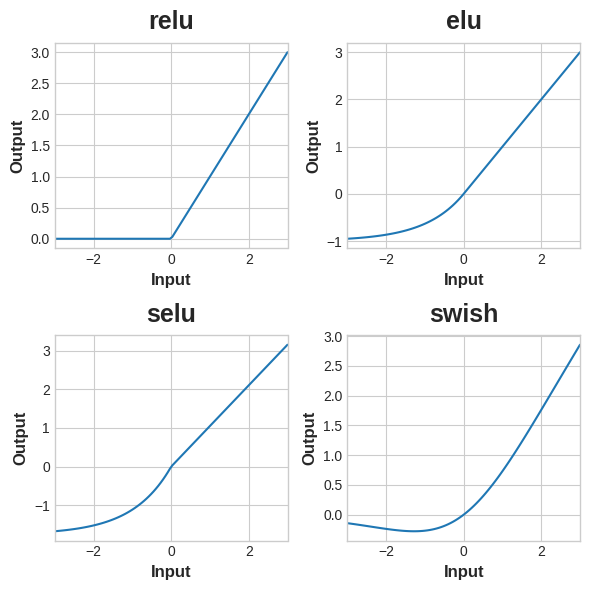

In [6]:
ELU, SeLU, SWISH = "elu", "selu", "swish"

X = tf.linspace(-3.0, 3.0, 100)

plt.figure(dpi=100)
fig, axes = plt.subplots(2, 2, figsize=(6, 6))

for ax, fun_name in list(zip(axes.flatten(), [ReLU, ELU, SeLU, SWISH])):
    activation_layer = layers.Activation(fun_name)
    y = activation_layer(X) # once created, a layer is callable just like a function
    sns.lineplot(ax=ax, x=X, y=y)
    ax.set_title(fun_name)
    ax.set_xlim(-3, 3)
    ax.set_xlabel("Input")
    ax.set_ylabel("Output")
    
plt.tight_layout()
plt.show()    